## You work as a junior data analyst for an e-commerce company.

The company has provided historical order data and wants you to investigate:
- Which product categories generate the most revenue?
- Which regions contribute the most sales?
- Are there any seasonal sales patterns?
- Who are the company's most valuable customers?
- Are there any data quality issues that need fixing?
Your job is to explore the dataset, clean it, analyze it, and present meaningful findings.

In [2]:
# Generating the data set 
import numpy as np
import pandas as pd

np.random.seed(42)

n = 600

categories = [
    'Electronics', 'Clothing',
    'Furniture', 'Books', 'Sports'
]

regions = ['North', 'South', 'East', 'West']

payment_methods = [
    'UPI', 'Credit Card',
    'Debit Card', 'Cash'
]

df = pd.DataFrame({
    'order_id': np.arange(1001, 1001+n),
    'customer_id': np.random.randint(101, 251, n),
    'order_date': pd.to_datetime(
        np.random.choice(
            pd.date_range('2025-01-01', '2025-12-31'),
            n
        )
    ),
    'product_category': np.random.choice(
        categories, n
    ),
    'region': np.random.choice(regions, n),
    'quantity': np.random.randint(1, 8, n),
    'unit_price': np.random.randint(100, 5000, n),
    'payment_method': np.random.choice(
        payment_methods, n
    ),
    'discount': np.random.choice(
        [0, 5, 10, 15, 20], n
    )
})

# Introduce some missing values intentionally
df.loc[np.random.choice(n, 15), 'unit_price'] = np.nan
df.loc[np.random.choice(n, 10), 'region'] = np.nan

# Introduce a few duplicate records
df = pd.concat(
    [df, df.sample(5, random_state=42)],
    ignore_index=True
)

# df.head()
df.sample(5)

,order_id,customer_id,order_date,product_category,region,quantity,unit_price,payment_method,discount
161,1162,181,2025-07-21,Electronics,North,3,2697.0,Debit Card,10
323,1324,158,2025-04-14,Books,West,3,1975.0,Cash,15
456,1457,212,2025-12-03,Clothing,South,1,2821.0,Cash,15
588,1589,159,2025-10-20,Electronics,West,2,3275.0,UPI,5
172,1173,168,2025-01-25,Electronics,South,7,4465.0,Cash,20


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          605 non-null    int64         
 1   customer_id       605 non-null    int32         
 2   order_date        605 non-null    datetime64[ns]
 3   product_category  605 non-null    object        
 4   region            595 non-null    object        
 5   quantity          605 non-null    int32         
 6   unit_price        590 non-null    float64       
 7   payment_method    605 non-null    object        
 8   discount          605 non-null    int64         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(2), object(3)
memory usage: 37.9+ KB


In [5]:
# df.info()    Null values in 'region' and 'unit_price'
df.describe()  # Avg quantity ordered by a person : 4 and avg unit price : 2556 

,order_id,customer_id,order_date,quantity,unit_price,discount
count,605.000000,605.000000,605,605.000000,590.000000,605.000000
mean,1300.259504,178.761983,2025-06-30 08:38:52.561983488,4.036364,2556.330508,9.611570
min,1001.000000,101.000000,2025-01-01 00:00:00,1.000000,106.000000,0.000000
25%,1150.000000,141.000000,2025-03-30 00:00:00,2.000000,1407.500000,5.000000
50%,1300.000000,184.000000,2025-06-28 00:00:00,4.000000,2443.000000,10.000000
75%,1450.000000,217.000000,2025-10-09 00:00:00,6.000000,3749.500000,15.000000
max,1600.000000,250.000000,2025-12-31 00:00:00,7.000000,4997.000000,20.000000
std,173.511380,44.219907,NaN,1.983041,1371.866958,7.179547


In [7]:
df.isna().sum()

order_id             0
customer_id          0
order_date           0
product_category     0
region              10
quantity             0
unit_price          15
payment_method       0
discount             0
dtype: int64

In [8]:
# Missing value handling 
# Region -- Replaced by mode value
df2 = df.copy()

df2['region'] = df2['region'].fillna(df2['region'].mode()[0])
df2.isna().sum()

order_id             0
customer_id          0
order_date           0
product_category     0
region               0
quantity             0
unit_price          15
payment_method       0
discount             0
dtype: int64

In [10]:
# Unit price replaced by avg value
df2['unit_price'] = df2['unit_price'].fillna(df2['unit_price'].mean())
df2.isna().sum()

order_id            0
customer_id         0
order_date          0
product_category    0
region              0
quantity            0
unit_price          0
payment_method      0
discount            0
dtype: int64

In [11]:
df2.tail()

,order_id,customer_id,order_date,product_category,region,quantity,unit_price,payment_method,discount
600,1111,190,2025-08-06,Sports,North,2,1341.0,Credit Card,15
601,1420,129,2025-11-15,Sports,East,7,3375.0,Cash,20
602,1566,245,2025-02-28,Electronics,South,3,2411.0,Debit Card,20
603,1078,171,2025-09-06,Books,South,2,769.0,Cash,10
604,1182,244,2025-02-03,Sports,South,5,2431.0,Cash,15


In [12]:
df2.duplicated().sum()

np.int64(5)

In [13]:
df3 = df2.copy()

# Drop duplicate rows
df3 = df3.drop_duplicates()
df3.duplicated().sum()

np.int64(0)

In [16]:
print("No of unique product categories : " ,df['product_category'].nunique())
print(f"No of unique customers : {df['customer_id'].nunique()}")

No of unique product categories :  5
No of unique customers : 146


In [19]:
df3['discount'] = df3['discount'].astype("float64")
df3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          600 non-null    int64         
 1   customer_id       600 non-null    int32         
 2   order_date        600 non-null    datetime64[ns]
 3   product_category  600 non-null    object        
 4   region            600 non-null    object        
 5   quantity          600 non-null    int32         
 6   unit_price        600 non-null    float64       
 7   payment_method    600 non-null    object        
 8   discount          600 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int32(2), int64(1), object(3)
memory usage: 42.2+ KB


In [21]:
df4 = df3.copy()

df4 = df4.assign(total_amount = lambda x : x['unit_price'] * x['quantity'] * (1 - x['discount']/100) )
df4.head()

,order_id,customer_id,order_date,product_category,region,quantity,unit_price,payment_method,discount,total_amount
0,1001,203,2025-09-16,Electronics,West,5,3748.0,UPI,5.0,17803.0
1,1002,193,2025-01-23,Clothing,West,3,3688.0,UPI,20.0,8851.2
2,1003,115,2025-02-22,Books,West,6,1637.0,Cash,15.0,8348.7
3,1004,207,2025-06-14,Sports,West,2,3237.0,Credit Card,15.0,5502.9
4,1005,172,2025-07-21,Clothing,East,4,197.0,UPI,5.0,748.6


In [41]:
print(f"Total revenue acrosss all categories : {df4['total_amount'].sum()}")
print("Category wise revenue : ")
categ_wise_rev = df4.groupby('product_category')['total_amount'].sum().sort_values(ascending=False)
categ_wise_rev

Total revenue acrosss all categories : 5619661.731355932
Category wise revenue : 


product_category
Sports         1.229810e+06
Clothing       1.154061e+06
Electronics    1.125984e+06
Books          1.093632e+06
Furniture      1.016175e+06
Name: total_amount, dtype: float64

In [45]:
region_wise_summary = df4.groupby('region').agg(
    total_orders = ('order_id','count'),
    max_profit = ('total_amount','max'),
    most_used_payment_method = ('payment_method',lambda x: x.mode().tolist())
)
print(type(region_wise_summary), region_wise_summary.columns)
region_wise_summary

<class 'pandas.core.frame.DataFrame'> Index(['total_orders', 'max_profit', 'most_used_payment_method'], dtype='object')


,total_orders,max_profit,most_used_payment_method
region,,,
East,132,29950.2,[UPI]
North,149,33159.0,[UPI]
South,174,29975.4,[Cash]
West,145,33824.0,[Credit Card]


In [26]:
top5_cust = df4.groupby('customer_id')['total_amount'].sum().sort_values(ascending=False).head()
top5_cust

customer_id
121    102377.65
193     93726.05
199     92940.40
228     91169.75
230     90090.45
Name: total_amount, dtype: float64

In [29]:
categ_wise_aov = df4.groupby('product_category').agg(
    total_orders = ('order_id','count'),
    aov = ('total_amount', 'mean')
)
categ_wise_aov = categ_wise_aov.sort_values(
    by='aov',
    ascending=False
)
categ_wise_aov

,total_orders,aov
product_category,,
Sports,123,9998.451526
Clothing,122,9459.513573
Books,116,9427.863855
Electronics,120,9383.203273
Furniture,119,8539.285191


In [46]:
region_wise_rev = df4.groupby('region')['total_amount'].sum().sort_values(ascending=False)
region_wise_rev


region
West     1.489668e+06
South    1.479462e+06
North    1.408018e+06
East     1.242515e+06
Name: total_amount, dtype: float64

In [30]:
# Visialisation of derived insights
import matplotlib.pyplot as plt


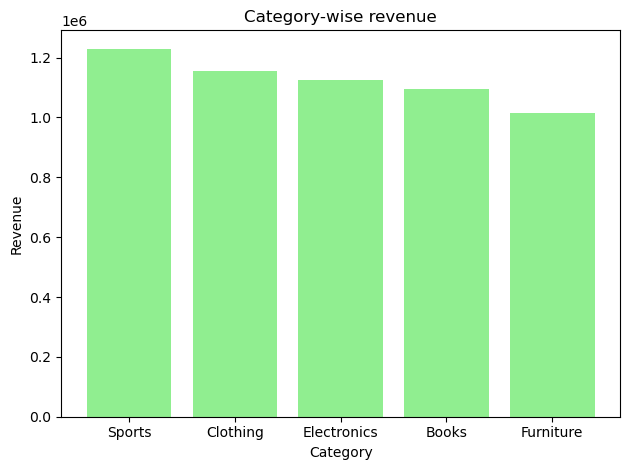

In [43]:
plt.bar(
    x=categ_wise_rev.index,
    height=categ_wise_rev.values,
    color='lightgreen'
)
plt.title("Category-wise revenue")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

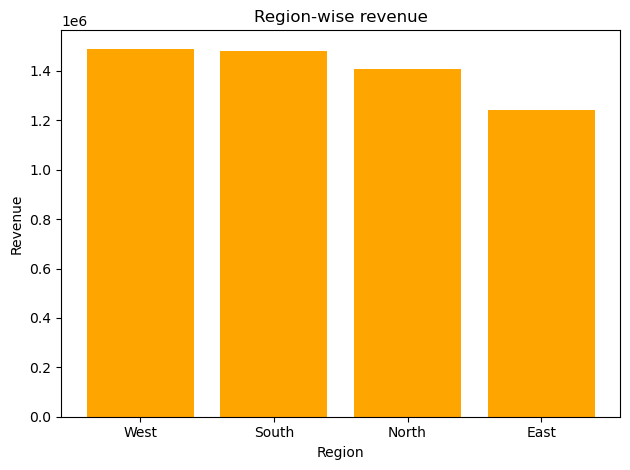

In [49]:
plt.bar(
    x=region_wise_rev.index,
    height=region_wise_rev.values,
    color='orange'
)
plt.title("Region-wise revenue")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

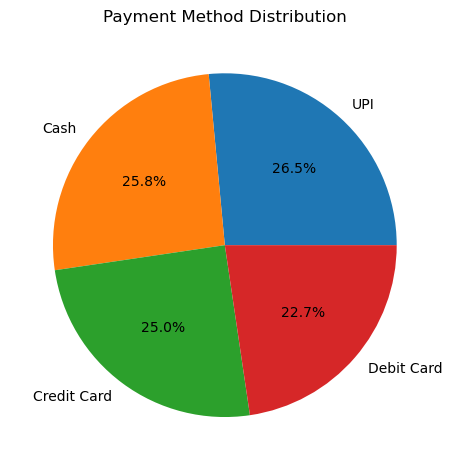

In [51]:
payment_dist = df4['payment_method'].value_counts()

plt.pie(
    payment_dist.values,
    labels=payment_dist.index,
    autopct='%1.1f%%'
)

plt.title("Payment Method Distribution")
plt.tight_layout()
plt.show()

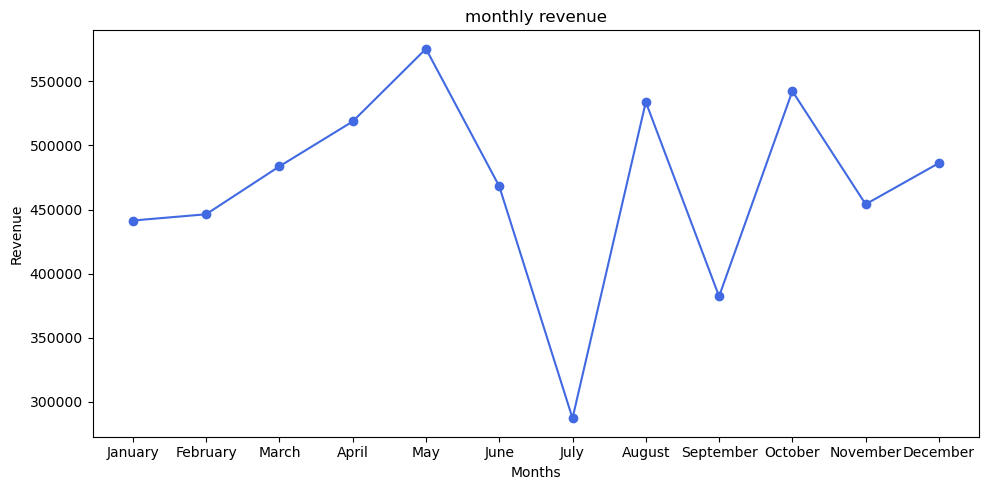

In [52]:
# Monthly revenue 
monthly_revenue = (
    df4.groupby(df4['order_date'].dt.month)['total_amount']
    .sum()
)
monthly_revenue.index = (
    pd.to_datetime(monthly_revenue.index, format='%m')
    .month_name()
)
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue.index, monthly_revenue.values, color='royalblue',linestyle='-', marker='o')
plt.title('monthly revenue')
plt.xlabel('Months')
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

## Final insights discovered : 
- In may , revenue was alltime high and July hit alltime lowest in terms of revenue.
- Sports is our most profitable category while Furniture being the least one.
- West and South regions are most profitable regions, while East being the least one.
- Only South region uses 'Cash' as their main payment method , while others use UPI and credit card.
- South has the most no of orders
- UPI is the most used method across all regions.